In [27]:
import sys
import os
import torch
import argparse
import yaml
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from train_sam_ppo import main as train_func
import gymnasium as gym 
from sam_ppo_continuous_efficient import PPO_continuous

In [28]:
# 1. Prepariamo le dimensioni (devono corrispondere al tuo Hopper-v4)
env_temp = gym.make("Hopper-v4")
state_dim = env_temp.observation_space.shape[0]
action_dim = env_temp.action_space.shape[0]
max_action = float(env_temp.action_space.high[0])

# 2. Definiamo gli agenti (usando i parametri dello YAML)
def load_agent(path, use_sam=False):
    # Carica la configurazione di base dal file YAML
    with open("configs/Hopper.yaml", 'r') as file:
        config = yaml.safe_load(file)
    
    # Crea un oggetto args contenente i parametri dello YAML
    args = argparse.Namespace(**config)
    
    # Aggiungi le dimensioni specifiche lette dall'environment
    args.state_dim = state_dim
    args.action_dim = action_dim
    args.max_action = max_action
    
    # Impostazioni specifiche per SAM PPO
    args.use_sam = use_sam
    args.rho = 0.01 if use_sam else 0.0
    
    # Impostazioni di default aggiuntive richieste dalla classe che potrebbero mancare nello YAML
    args.set_adam_eps = False
    args.use_adv_norm = False
    args.adaptive_alpha = False
    args.use_grad_clip = config.get("use_grad_clip", True)
    args.use_lr_decay = config.get("use_lr_decay", True)
    args.use_orthogonal_init = config.get("use_orthogonal_init", True)
    args.use_tanh = config.get("use_tanh", True)
    # Istanziamo l'agente passando il singolo oggetto args
    agent = PPO_continuous(args)
    
    # Carichiamo i pesi salvati
    agent.actor.load_state_dict(torch.load(path))
    agent.actor.eval() # Impostiamo in modalità valutazione
    
    return agent

# 1. Definiamo una funzione di caricamento universale
def get_agent(env_name, model_path, config_path, use_sam=False):
    # Ricava le dimensioni direttamente dall'ambiente corretto
    env_temp = gym.make(env_name)
    
    with open(config_path, 'r') as file:
        config = yaml.safe_load(file)
        
    args = argparse.Namespace(**config)
    args.state_dim = env_temp.observation_space.shape[0]
    args.action_dim = env_temp.action_space.shape[0]
    args.max_action = float(env_temp.action_space.high[0])
    
    args.use_sam = use_sam
    args.rho = config.get('rho', 0.01) if use_sam else 0.0
    
    args.set_adam_eps = False
    args.use_adv_norm = False
    args.adaptive_alpha = False
    args.use_grad_clip = config.get("use_grad_clip", True)
    args.use_lr_decay = config.get("use_lr_decay", True)
    args.use_orthogonal_init = config.get("use_orthogonal_init", True)
    args.use_tanh = config.get("use_tanh", True)

    agent = PPO_continuous(args)
    agent.actor.load_state_dict(torch.load(model_path))
    agent.actor.eval()
    return agent



# 2. Carichiamo tutti i 4 agenti
print("Caricamento modelli in corso...")
hopper_sam = get_agent("Hopper-v4", "./models/SAM_PPO_Hopper-v4_rho_0.01_default_actor", "configs/Hopper.yaml", use_sam=True)
hopper_ppo = get_agent("Hopper-v4", "./models/PPO_Hopper-v4_default_actor", "configs/Hopper.yaml", use_sam=False)

walker_sam = get_agent("Walker2d-v4", "./models/SAM_PPO_Walker2d-v4_rho_0.008_default_actor", "configs/walker.yaml", use_sam=True)
walker_ppo = get_agent("Walker2d-v4", "./models/PPO_Walker2d-v4_default_actor", "configs/walker.yaml", use_sam=False)
print("Modelli caricati con successo!\n")


# 3. Carichiamo i file (Modifica i nomi dei file se diversi!)
try:
    # Removed the .pth extension, added _actor
    sam_agent = load_agent("./models/SAM_PPO_Hopper-v4_rho_0.01_default_actor", use_sam=True)
    
    # If you haven't trained standard PPO, you can comment this out or train it first
    # ppo_agent = load_agent("./models/PPO_Hopper-v4_default_actor", use_sam=False)
    
    print("Agenti caricati con successo! ")
except Exception as e:
    print(f"Errore: {e}")

# Eseguiamo le valutazioni
noise_range = np.linspace(0, 0.5, 6)
hopper_sam_rewards, hopper_ppo_rewards = [], []
walker_sam_rewards, walker_ppo_rewards = [], []

print("Valutazione Hopper-v4...")
for noise in noise_range:
    hopper_sam_rewards.append(evaluate_policy(hopper_sam, "Hopper-v4", noise))
    hopper_ppo_rewards.append(evaluate_policy(hopper_ppo, "Hopper-v4", noise))

print("Valutazione Walker2d-v4...")
for noise in noise_range:
    walker_sam_rewards.append(evaluate_policy(walker_sam, "Walker2d-v4", noise))
    walker_ppo_rewards.append(evaluate_policy(walker_ppo, "Walker2d-v4", noise))


/opt/anaconda3/envs/rrl_env/lib/python3.9/site-packages/gymnasium/envs/registration.py:519: DeprecationWarning: WARN: The environment Hopper-v4 is out of date. You should consider upgrading to version `v5`.
  logger.deprecation(
/opt/anaconda3/envs/rrl_env/lib/python3.9/site-packages/gymnasium/envs/registration.py:519: DeprecationWarning: WARN: The environment Walker2d-v4 is out of date. You should consider upgrading to version `v5`.
  logger.deprecation(


Caricamento modelli in corso...
------use_orthogonal_init------
------use_orthogonal_init------
Use SAM: True, rho: 0.01
------use_orthogonal_init------
------use_orthogonal_init------
Use SAM: False, rho: 0.0
------use_orthogonal_init------
------use_orthogonal_init------
Use SAM: True, rho: 0.008
------use_orthogonal_init------
------use_orthogonal_init------
Use SAM: False, rho: 0.0
Modelli caricati con successo!

------use_orthogonal_init------
------use_orthogonal_init------
Use SAM: True, rho: 0.01
Agenti caricati con successo! 
Valutazione Hopper-v4...
Valutazione Walker2d-v4...


In [29]:
def evaluate_policy(agent, env_name, noise_std, episodes=10):
    env = gym.make(env_name)
    total_reward = 0
    
    for _ in range(episodes):
        state, _ = env.reset()
        done = False
        while not done:
            # Prendi l'azione dalla policy (senza gradienti)
            with torch.no_grad():
                state_tensor = torch.FloatTensor(state).unsqueeze(0)
                action = agent.actor(state_tensor).numpy().flatten()
            
            # AGGIUNGI IL RUMORE (Il cuore del test di robustezza)
            if noise_std > 0:
                noise = np.random.normal(0, noise_std, size=action.shape)
                action = action + noise
            
            # Clip dell'azione per non uscire dai limiti dell'ambiente
            action = np.clip(action, -1.0, 1.0)
            
            state, reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated
            total_reward += reward
            
    return total_reward / episodes

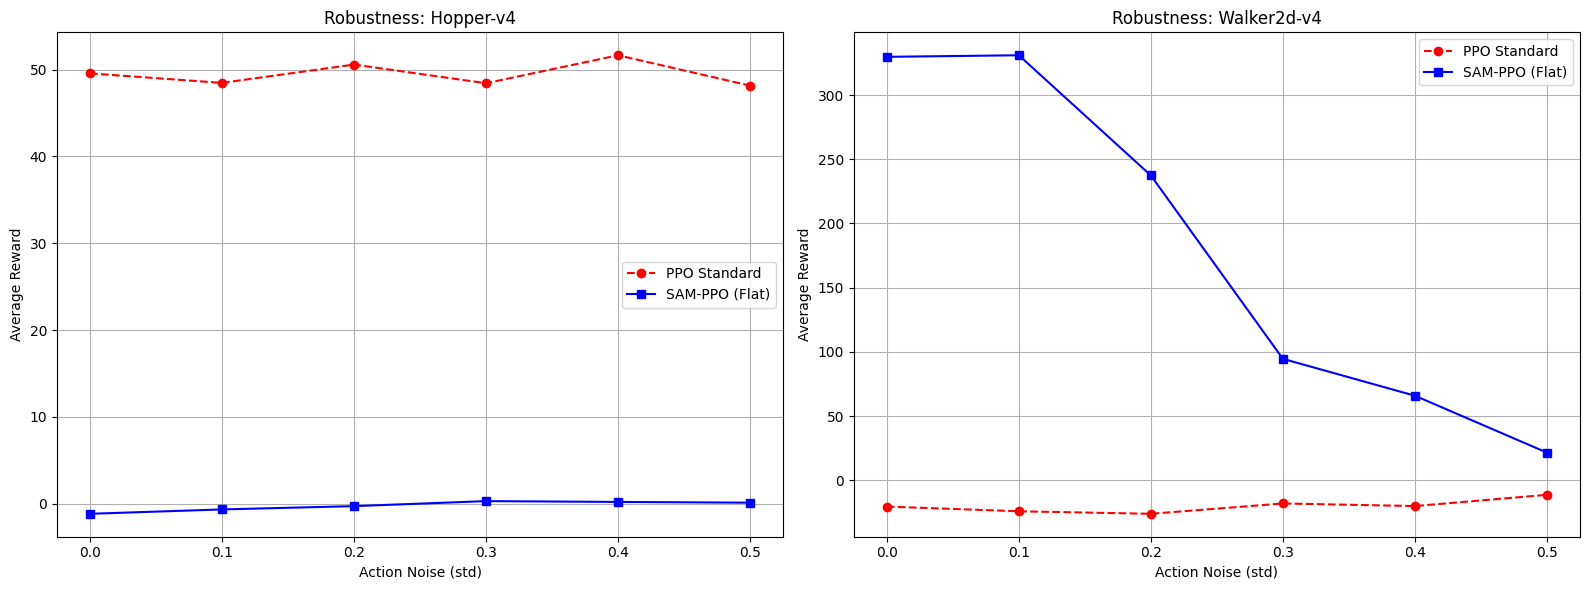

In [30]:
# 4. Creiamo il grafico
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].plot(noise_range, hopper_ppo_rewards, label='PPO Standard', marker='o', color='red', linestyle='--')
axes[0].plot(noise_range, hopper_sam_rewards, label='SAM-PPO (Flat)', marker='s', color='blue', linestyle='-')
axes[0].set_title('Robustness: Hopper-v4')
axes[0].set_xlabel('Action Noise (std)')
axes[0].set_ylabel('Average Reward')
axes[0].legend()
axes[0].grid(True)

axes[1].plot(noise_range, walker_ppo_rewards, label='PPO Standard', marker='o', color='red', linestyle='--')
axes[1].plot(noise_range, walker_sam_rewards, label='SAM-PPO (Flat)', marker='s', color='blue', linestyle='-')
axes[1].set_title('Robustness: Walker2d-v4')
axes[1].set_xlabel('Action Noise (std)')
axes[1].set_ylabel('Average Reward')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig('comparison_results.png', dpi=300)
plt.show()
